# Project Deliverable #2: Predicting Mortgage Application Denials with Tree Ensembles and SVM

**GRAD 50800 - Data Analytics · Bruno Cavagnaro**

**Data:** Home Mortgage Disclosure Act (HMDA) Loan/Application Register, 2025, Tippecanoe County, IN (the dataset chosen in Deliverable #1).

**Question:** using only information available when the application is filed, how well can we predict whether a lender **denies** a mortgage application, and which application characteristics drive that decision?

**Week 6 methods:** Decision Tree, **Random Forest**, Bagging, AdaBoost, **Gradient Boosting**, **Support Vector Machine**, and a **Stacking** ensemble, compared against a logistic-regression baseline.

**Contents**
1. Data: load the county extract and define the sample and target
2. Feature engineering and leakage control
3. Exploratory visualizations
4. Model comparison (5-fold cross-validation)
5. Tuning the champion models
6. Test-set evaluation (ROC, precision-recall, calibration, confusion matrix)
7. Interpretation (permutation importance, partial dependence)
8. Fair-lending check by demographic group
9. **One-page analysis**

## 0. Setup

In [1]:
from pathlib import Path
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     RandomizedSearchCV, cross_val_predict)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, BaggingClassifier, AdaBoostClassifier,
                              HistGradientBoostingClassifier, StackingClassifier)
from sklearn.svm import SVC
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, brier_score_loss, confusion_matrix,
                             classification_report, balanced_accuracy_score, f1_score)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 508

## 1. Data

Deliverable #1 filtered the 5 GB national 2025 file down to Tippecanoe County (FIPS `18157`, 7,124 records). That step is repeated here, keeping **all 99 columns**, and the result is saved once as `data/hmda_2025_tippecanoe.csv`. If the extract already exists, it is read directly.

In [2]:
COUNTY = "18157"                       # Tippecanoe County, IN

def find_dir():
    for d in [Path("data"), Path("project_deliverable/data")]:
        if (d / "hmda_2025_tippecanoe.csv").exists() or (d / "year_2025.csv").exists():
            return d
    raise FileNotFoundError("Run the notebook from the course folder or from project_deliverable/")

DATA_DIR = find_dir()
EXTRACT = DATA_DIR / "hmda_2025_tippecanoe.csv"

if not EXTRACT.exists():
    # Same lazy/streaming approach as Deliverable #1, but keeping every column
    import polars as pl
    lf = pl.scan_csv(DATA_DIR / "year_2025.csv", infer_schema=False)
    lf.filter(pl.col("county_code") == COUNTY).collect(engine="streaming").write_csv(EXTRACT)

raw = pd.read_csv(EXTRACT, dtype=str)
print(f"County extract: {raw.shape[0]:,} records x {raw.shape[1]} columns  ({EXTRACT})")

County extract: 7,124 records x 99 columns  (data/hmda_2025_tippecanoe.csv)


In [3]:
ACTION = {"1": "Originated", "2": "Approved, not accepted", "3": "Denied", "4": "Withdrawn",
          "5": "File closed (incomplete)", "6": "Purchased loan", "7": "Preapproval denied",
          "8": "Preapproval approved, not accepted"}
raw["action_taken"].map(ACTION).value_counts().to_frame("records")

,records
action_taken,
Originated,4350
Denied,871
Withdrawn,718
Purchased loan,637
File closed (incomplete),304
"Approved, not accepted",234
"Preapproval approved, not accepted",7
Preapproval denied,3


**Sample definition.**
* **Target:** `denied = 1` if `action_taken = 3` (application denied). `denied = 0` if the lender approved the application (`1` originated, or `2` approved but not accepted by the applicant).
* **Excluded:** withdrawn and incomplete files (the lender never made a credit decision), purchased loans (not decided by the reporting lender) and preapproval requests.
* **Excluded:** applications from lenders with **partial HMDA exemptions** (`aus-1 = 1111`). They report "Exempt" for DTI, LTV, property value and most other underwriting fields, so the model has nothing to learn from for them.

In [4]:
df = raw[raw["action_taken"].isin(["1", "2", "3"])].copy()
n_decided = len(df)
df = df[df["aus-1"] != "1111"].copy()
df["denied"] = (df["action_taken"] == "3").astype(int)

print(f"Decided applications: {n_decided:,} -> after removing exempt reporters: {len(df):,}")
print(f"Denial rate: {df['denied'].mean():.1%}  ({df['denied'].sum():,} denied)")
print(f"Distinct lenders: {df['lei'].nunique()}")

Decided applications: 5,455 -> after removing exempt reporters: 5,147
Denial rate: 16.2%  (834 denied)
Distinct lenders: 238


## 2. Feature engineering and leakage control

**Excluded on purpose:**

| Column(s) | Reason |
|---|---|
| `interest_rate`, `rate_spread`, `total_loan_costs`, `origination_charges`, `discount_points`, `lender_credits`, `purchaser_type` | **Leakage**: reported only for originated loans (100% missing for denials, or `purchaser_type = 0`). |
| `hoepa_status`, `initially_payable_to_institution` | **Leakage**: the code "not applicable" is used for loans that were not originated (60-77% denial rate). |
| `denial_reason-*` | The outcome itself. |
| `derived_race`, `derived_ethnicity`, `derived_sex`, `applicant_age`, `tract_minority_population_percent` | **Protected characteristics (or a close proxy).** Leaving them out keeps the model consistent with fair-lending practice (ECOA / Regulation B). They are used only *after* modelling, in Section 8, to check the model for disparities. |
| `lei` (lender ID) | Very predictive (lenders differ in product mix and appetite) but has 250+ levels. Left for the final project (target encoding). |

**Engineered features:**
* `dti`: HMDA reports the debt-to-income ratio partly in bands (`<20%`, `20%-<30%`, `30%-<36%`, `50%-60%`, `>60%`) and partly as exact integers (36-49). Each band is converted to its midpoint, giving one ordinal-numeric column.
* `log_loan`, `log_property`, `log_income`: amounts are very right-skewed (a few multimillion-dollar records). The log scale helps the SVM and logistic regression; trees are unaffected by monotone transforms. Zero or negative incomes are set to missing.
* `ltv`: combined loan-to-value ratio, capped at 250% to limit data-entry outliers.
* `loan_to_income`: loan amount ÷ annual income, a simple measure of affordability.
* `has_coapplicant`, `multi_unit`, and an `owner-occupied share` for the census tract.
* Rare categories (< 30 applications) are grouped into `"other"`.

In [5]:
DTI_MAP = {"<20%": 15, "20%-<30%": 25, "30%-<36%": 33, "50%-60%": 55, ">60%": 65}

def to_num(s):
    return pd.to_numeric(s, errors="coerce")          # "NA" / "Exempt" -> NaN

def build_features(d: pd.DataFrame) -> pd.DataFrame:
    X = pd.DataFrame(index=d.index)
    loan, prop, inc = to_num(d["loan_amount"]), to_num(d["property_value"]), to_num(d["income"])
    inc = inc.where(inc > 0)                           # income in $000s; <= 0 is not usable
    X["log_loan"] = np.log(loan)
    X["log_property"] = np.log(prop)
    X["log_income"] = np.log(inc)
    X["loan_to_income"] = (loan / 1000) / inc
    X["ltv"] = to_num(d["loan_to_value_ratio"]).clip(upper=250)
    X["dti"] = d["debt_to_income_ratio"].map(DTI_MAP).fillna(to_num(d["debt_to_income_ratio"]))
    X["loan_term"] = to_num(d["loan_term"])
    X["tract_income_pct"] = to_num(d["tract_to_msa_income_percentage"])
    X["tract_housing_age"] = to_num(d["tract_median_age_of_housing_units"])
    X["tract_owner_share"] = (to_num(d["tract_owner_occupied_units"]) /
                              to_num(d["tract_one_to_four_family_homes"]).replace(0, np.nan)).clip(upper=1.5)

    cat = {
        "loan_type": d["loan_type"].map({"1": "conventional", "2": "FHA", "3": "VA", "4": "USDA"}),
        "loan_purpose": d["loan_purpose"].map({"1": "purchase", "2": "home_improvement", "31": "refinance",
                                               "32": "cash_out_refi", "4": "other_purpose", "5": "other_purpose"}),
        "lien": d["lien_status"].map({"1": "first", "2": "subordinate"}),
        "occupancy": d["occupancy_type"].map({"1": "principal", "2": "second", "3": "investment"}),
        "open_end_loc": d["open-end_line_of_credit"].map({"1": "yes", "2": "no"}),
        "business_purpose": d["business_or_commercial_purpose"].map({"1": "yes", "2": "no"}),
        "manufactured": d["construction_method"].map({"1": "no", "2": "yes"}),
        "multi_unit": np.where(d["total_units"] == "1", "no", "yes"),
        "direct_application": d["submission_of_application"].map({"1": "yes", "2": "no"}),
        "preapproval": d["preapproval"].map({"1": "requested", "2": "not_requested"}),
        "credit_score_model": d["applicant_credit_score_type"],
        "aus": d["aus-1"].map({"1": "DU", "2": "LPA", "3": "TOTAL", "4": "GUS", "5": "other",
                               "6": "not_applicable", "7": "internal"}),
        "has_coapplicant": np.where(d["co-applicant_credit_score_type"] == "10", "no", "yes"),
    }
    for k, v in cat.items():
        v = pd.Series(v, index=d.index).fillna("missing").astype(str)
        counts = v.value_counts()
        X[k] = v.where(v.map(counts) >= 30, "other")
    return X

X = build_features(df)
y = df["denied"]
NUM = X.select_dtypes("number").columns.tolist()
CAT = X.select_dtypes("object").columns.tolist()
print(f"{X.shape[1]} features: {len(NUM)} numeric, {len(CAT)} categorical")
display(X[NUM].describe().T.round(2))
display(X[NUM].isna().mean().mul(100).round(1).to_frame("% missing").T)

23 features: 10 numeric, 13 categorical


,count,mean,std,min,25%,50%,75%,max
log_loan,5147.0,11.91,0.93,8.52,11.35,12.13,12.52,17.69
log_property,4992.0,12.66,0.52,8.52,12.37,12.63,12.94,18.30
log_income,4748.0,4.56,0.65,0.00,4.13,4.53,4.96,7.97
loan_to_income,4748.0,2.10,2.82,0.02,0.85,1.88,2.95,115.00
ltv,4919.0,72.58,21.92,1.99,60.01,78.34,89.83,250.00
dti,4784.0,36.99,11.87,15.00,25.00,37.00,45.00,65.00
loan_term,5122.0,311.70,82.91,3.00,288.00,360.00,360.00,480.00
tract_income_pct,5147.0,109.38,31.47,0.00,87.00,105.00,130.00,176.00
tract_housing_age,5147.0,37.04,19.18,0.00,21.00,29.00,52.00,79.00
tract_owner_share,5140.0,0.73,0.16,0.00,0.62,0.80,0.84,0.99


,log_loan,log_property,log_income,loan_to_income,ltv,dti,loan_term,tract_income_pct,tract_housing_age,tract_owner_share
% missing,0.0,3.0,7.8,7.8,4.4,7.1,0.5,0.0,0.0,0.1


## 3. Exploratory visualizations

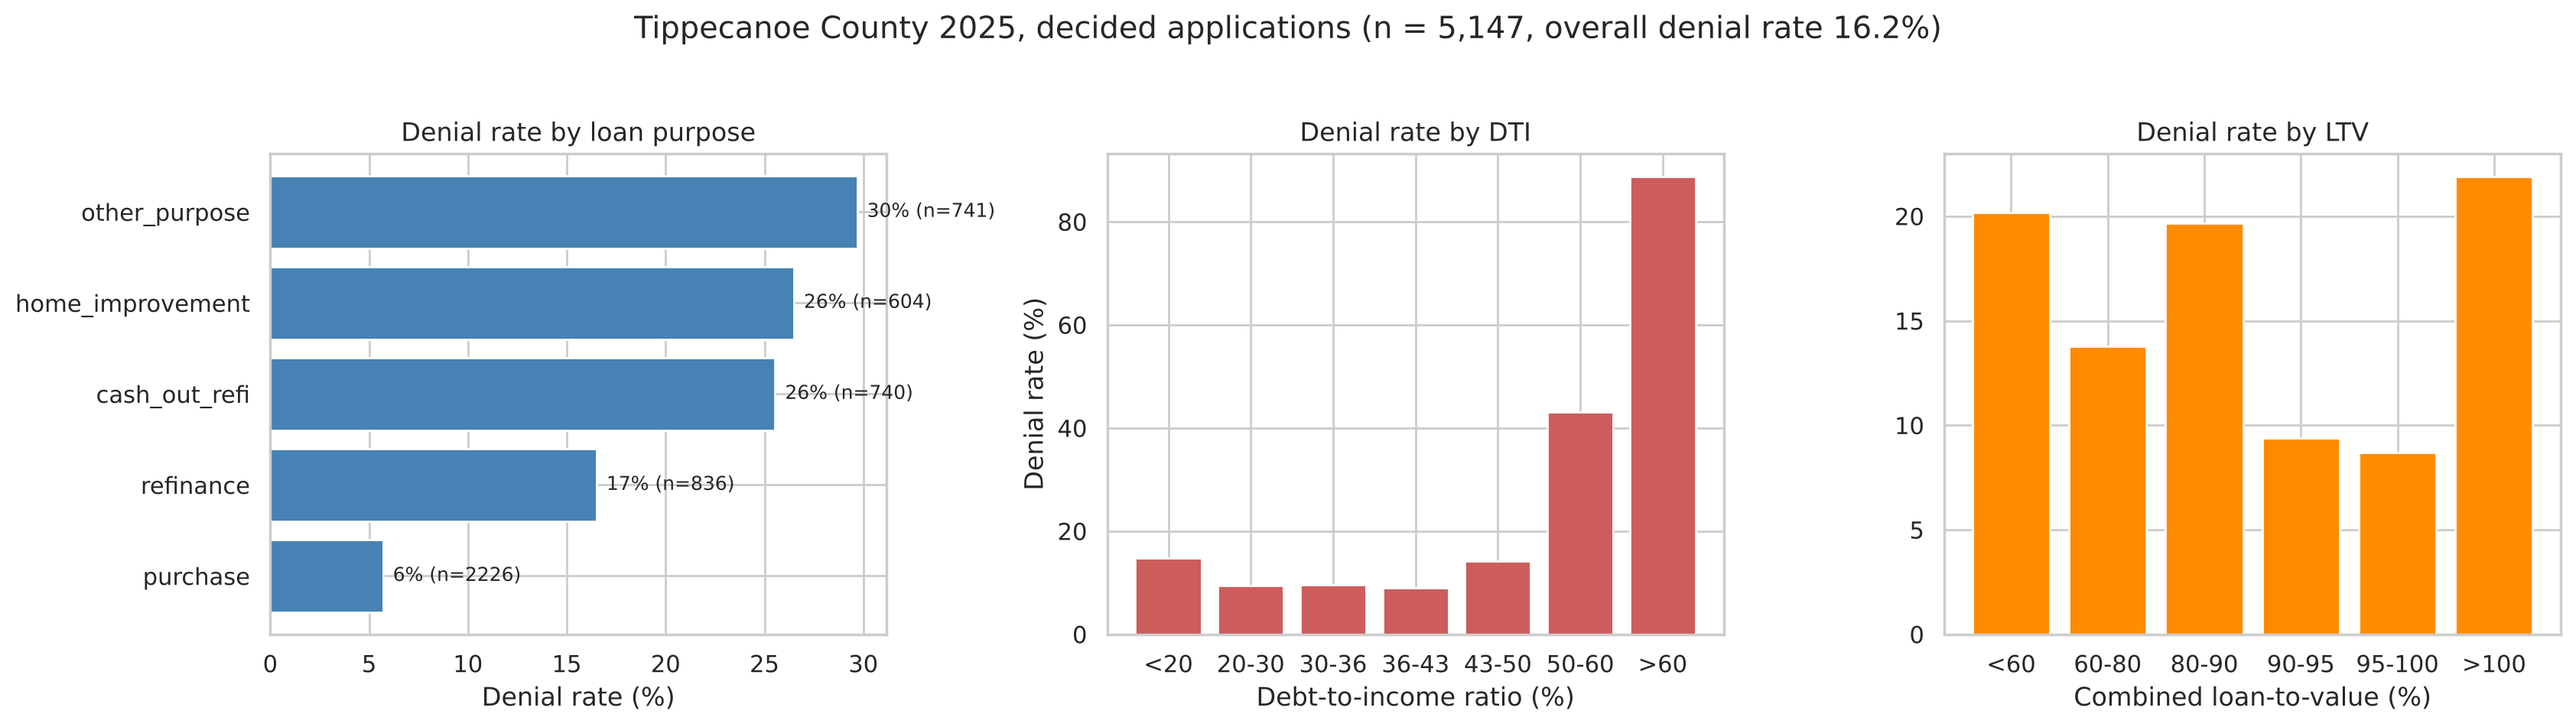

In [6]:
eda = X.assign(denied=y)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

p = eda.groupby("loan_purpose")["denied"].agg(["mean", "size"]).sort_values("mean")
axes[0].barh(p.index, p["mean"] * 100, color="steelblue")
for i, (m, n) in enumerate(zip(p["mean"], p["size"])):
    axes[0].text(m * 100 + .5, i, f"{m:.0%} (n={n})", va="center", fontsize=9)
axes[0].set_xlabel("Denial rate (%)"); axes[0].set_title("Denial rate by loan purpose")

eda["dti_band"] = pd.cut(eda["dti"], [0, 20, 30, 36, 43, 50, 60, 100],
                         labels=["<20", "20-30", "30-36", "36-43", "43-50", "50-60", ">60"], right=False)
b = eda.groupby("dti_band", observed=True)["denied"].mean() * 100
axes[1].bar(b.index.astype(str), b.values, color="indianred")
axes[1].set_xlabel("Debt-to-income ratio (%)"); axes[1].set_ylabel("Denial rate (%)")
axes[1].set_title("Denial rate by DTI")

eda["ltv_band"] = pd.cut(eda["ltv"], [0, 60, 80, 90, 95, 100, 250],
                         labels=["<60", "60-80", "80-90", "90-95", "95-100", ">100"])
b = eda.groupby("ltv_band", observed=True)["denied"].mean() * 100
axes[2].bar(b.index.astype(str), b.values, color="darkorange")
axes[2].set_xlabel("Combined loan-to-value (%)"); axes[2].set_title("Denial rate by LTV")
plt.suptitle(f"Tippecanoe County 2025, decided applications (n = {len(eda):,}, overall denial rate {y.mean():.1%})",
             y=1.03)
plt.tight_layout(); plt.show()

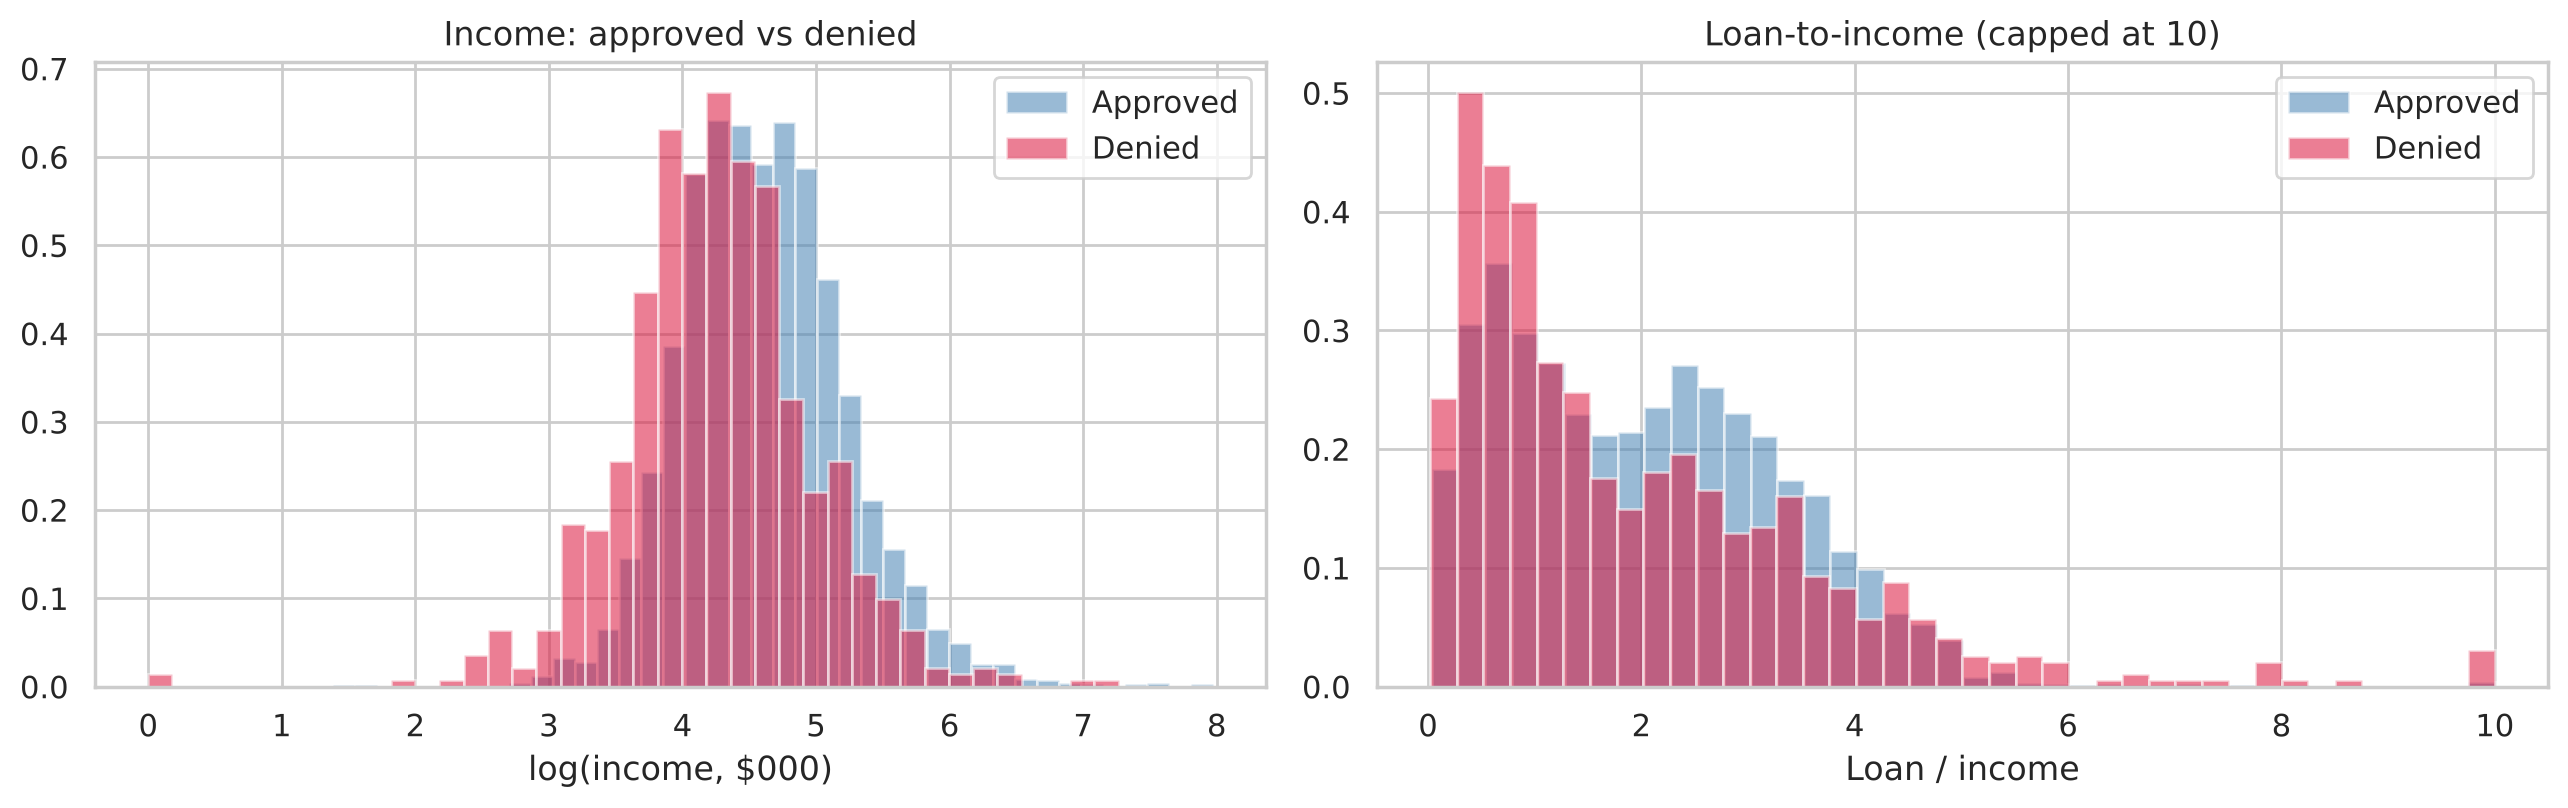

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, c, lab in [(axes[0], "log_income", "log(income, $000)"), (axes[1], "loan_to_income", "Loan / income")]:
    for k, colr, name in [(0, "steelblue", "Approved"), (1, "crimson", "Denied")]:
        v = eda.loc[eda["denied"] == k, c].dropna()
        if c == "loan_to_income":
            v = v.clip(upper=10)
        ax.hist(v, bins=40, alpha=.55, density=True, color=colr, label=name)
    ax.set_xlabel(lab); ax.legend()
axes[0].set_title("Income: approved vs denied"); axes[1].set_title("Loan-to-income (capped at 10)")
plt.tight_layout(); plt.show()

## 4. Model comparison (5-fold cross-validation on the training set)

* 75/25 train/test split, **stratified** on the target. The test set stays untouched until Section 6.
* Preprocessing goes **inside each pipeline**, so imputation and scaling are learned only from the training folds:
  * **Trees and ensembles:** median imputation plus missing-value indicator columns (being *missing*, such as no property value, is itself informative), and one-hot encoding of the categories. No scaling is needed, because trees split on thresholds.
  * **SVM and logistic regression:** the same, plus **standardization**, because both depend on distances and coefficient magnitudes.
  * **Histogram Gradient Boosting** handles missing values natively.
* **Class imbalance (16% denied):** `class_weight="balanced"` where available. The main metric is **ROC-AUC**, which does not depend on a threshold. I also report **PR-AUC** (average precision, more informative when the positive class is rare) and the **Brier score** (probability accuracy).

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y,
                                                    random_state=RANDOM_STATE)
print(f"Train: {len(X_train):,} ({y_train.mean():.1%} denied) | Test: {len(X_test):,} ({y_test.mean():.1%} denied)")

ohe = lambda: OneHotEncoder(handle_unknown="ignore", sparse_output=False)
prep_tree = ColumnTransformer([
    ("num", SimpleImputer(strategy="median", add_indicator=True), NUM),
    ("cat", ohe(), CAT)])
prep_scaled = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                      ("sc", StandardScaler())]), NUM),
    ("cat", ohe(), CAT)])
prep_hgb = ColumnTransformer([("num", "passthrough", NUM), ("cat", ohe(), CAT)])

models = {
    "Logistic regression (baseline)": Pipeline([("prep", prep_scaled),
        ("clf", LogisticRegression(max_iter=3000, class_weight="balanced", C=1.0))]),
    "Decision tree": Pipeline([("prep", prep_tree),
        ("clf", DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, class_weight="balanced",
                                       random_state=RANDOM_STATE))]),
    "Bagging (trees)": Pipeline([("prep", prep_tree),
        ("clf", BaggingClassifier(DecisionTreeClassifier(min_samples_leaf=5), n_estimators=200,
                                  random_state=RANDOM_STATE, n_jobs=-1))]),
    "Random forest": Pipeline([("prep", prep_tree),
        ("clf", RandomForestClassifier(n_estimators=500, min_samples_leaf=3, class_weight="balanced_subsample",
                                       random_state=RANDOM_STATE, n_jobs=-1))]),
    "AdaBoost": Pipeline([("prep", prep_tree),
        ("clf", AdaBoostClassifier(DecisionTreeClassifier(max_depth=2), n_estimators=300,
                                   learning_rate=0.1, random_state=RANDOM_STATE))]),
    "Gradient boosting (HistGB)": Pipeline([("prep", prep_hgb),
        ("clf", HistGradientBoostingClassifier(learning_rate=0.05, max_iter=400, max_leaf_nodes=15,
                                               min_samples_leaf=30, l2_regularization=1.0,
                                               early_stopping=False, random_state=RANDOM_STATE))]),
    "SVM (RBF kernel)": Pipeline([("prep", prep_scaled),
        ("clf", SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced",
                    probability=True, random_state=RANDOM_STATE))]),
}

cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "brier": "neg_brier_score",
           "bal_acc": "balanced_accuracy"}
rows = []
for name, mdl in models.items():
    t0 = time.time()
    r = cross_validate(mdl, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
    rows.append({"model": name, "ROC-AUC": r["test_roc_auc"].mean(), "ROC-AUC sd": r["test_roc_auc"].std(),
                 "PR-AUC": r["test_pr_auc"].mean(), "Brier": -r["test_brier"].mean(),
                 "Balanced acc.": r["test_bal_acc"].mean(), "seconds": time.time() - t0})
cv_results = pd.DataFrame(rows).set_index("model").sort_values("ROC-AUC", ascending=False)
cv_results.round(3)

Train: 3,860 (16.2% denied) | Test: 1,287 (16.2% denied)


,ROC-AUC,ROC-AUC sd,PR-AUC,Brier,Balanced acc.,seconds
model,,,,,,
Gradient boosting (HistGB),0.853,0.012,0.661,0.087,0.714,2.301
Random forest,0.852,0.019,0.637,0.103,0.716,6.269
Bagging (trees),0.847,0.018,0.657,0.088,0.698,8.842
SVM (RBF kernel),0.841,0.018,0.602,0.095,0.767,7.220
AdaBoost,0.839,0.022,0.600,0.124,0.645,5.706
Logistic regression (baseline),0.815,0.027,0.539,0.171,0.729,1.406
Decision tree,0.802,0.018,0.532,0.164,0.731,0.235


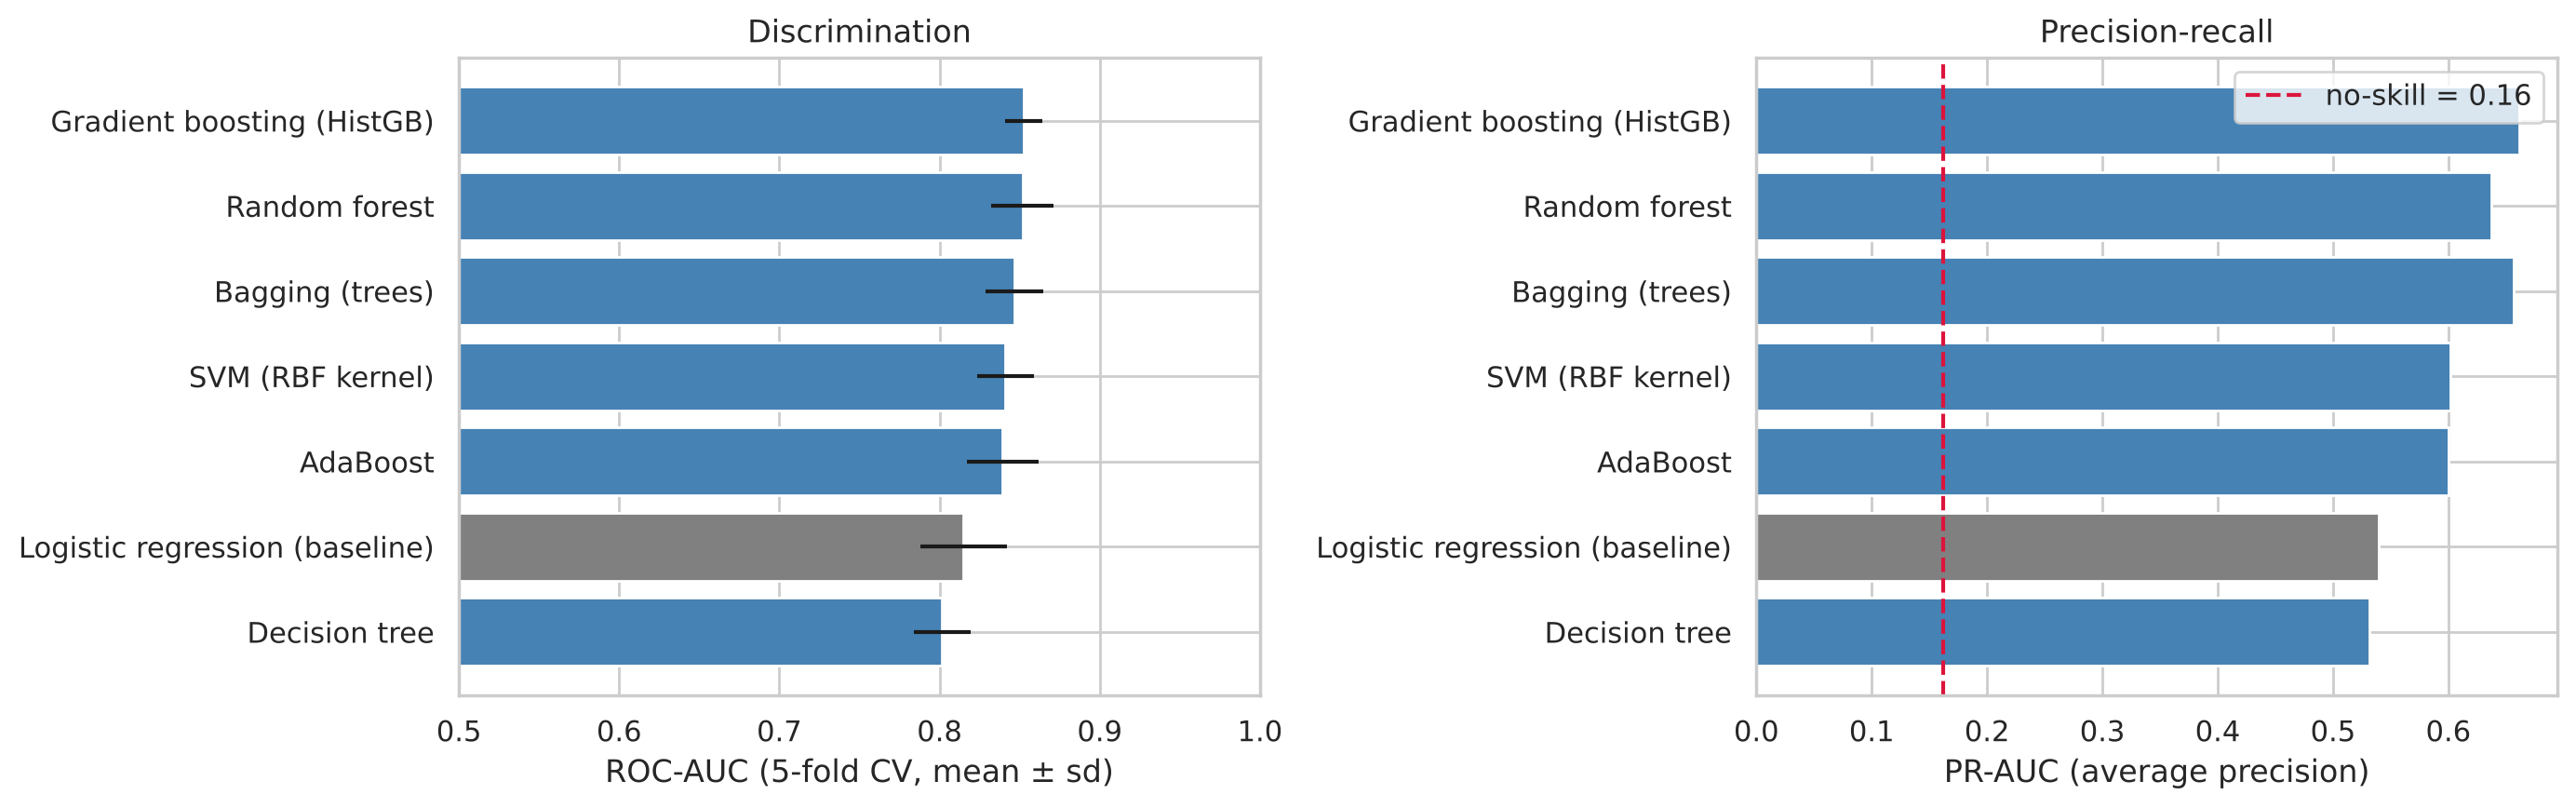

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
cr = cv_results.sort_values("ROC-AUC")
colors = ["grey" if "baseline" in m else "steelblue" for m in cr.index]
axes[0].barh(cr.index, cr["ROC-AUC"], xerr=cr["ROC-AUC sd"], color=colors)
axes[0].set_xlim(.5, 1); axes[0].set_xlabel("ROC-AUC (5-fold CV, mean ± sd)")
axes[0].set_title("Discrimination")
axes[1].barh(cr.index, cr["PR-AUC"], color=colors)
axes[1].axvline(y_train.mean(), color="crimson", ls="--", label=f"no-skill = {y_train.mean():.2f}")
axes[1].set_xlabel("PR-AUC (average precision)"); axes[1].set_title("Precision-recall"); axes[1].legend()
plt.tight_layout(); plt.show()

## 5. Tuning the two strongest ensembles, and stacking

A randomized search (5-fold CV, ROC-AUC) tunes the **random forest** and **gradient boosting**. A **stacking** ensemble then combines the tuned random forest, the tuned gradient boosting and the SVM through a logistic-regression meta-learner, which is trained on out-of-fold predictions.

In [10]:
rf_search = RandomizedSearchCV(
    models["Random forest"],
    {"clf__n_estimators": [300, 500, 800], "clf__max_depth": [None, 8, 12, 16],
     "clf__min_samples_leaf": [1, 3, 5, 10, 20], "clf__max_features": ["sqrt", 0.3, 0.5]},
    n_iter=20, cv=cv, scoring="roc_auc", n_jobs=-1, random_state=RANDOM_STATE).fit(X_train, y_train)

hgb_search = RandomizedSearchCV(
    models["Gradient boosting (HistGB)"],
    {"clf__learning_rate": [0.02, 0.05, 0.1], "clf__max_iter": [200, 400, 700],
     "clf__max_leaf_nodes": [7, 15, 31], "clf__min_samples_leaf": [20, 40, 80],
     "clf__l2_regularization": [0, 1, 5]},
    n_iter=25, cv=cv, scoring="roc_auc", n_jobs=-1, random_state=RANDOM_STATE).fit(X_train, y_train)

print(f"Random forest   best CV ROC-AUC = {rf_search.best_score_:.3f}  {rf_search.best_params_}")
print(f"Gradient boost. best CV ROC-AUC = {hgb_search.best_score_:.3f}  {hgb_search.best_params_}")

Random forest   best CV ROC-AUC = 0.853  {'clf__n_estimators': 800, 'clf__min_samples_leaf': 3, 'clf__max_features': 'sqrt', 'clf__max_depth': 16}
Gradient boost. best CV ROC-AUC = 0.859  {'clf__min_samples_leaf': 20, 'clf__max_leaf_nodes': 7, 'clf__max_iter': 400, 'clf__learning_rate': 0.02, 'clf__l2_regularization': 1}


In [11]:
stack = StackingClassifier(
    estimators=[("rf", rf_search.best_estimator_), ("hgb", hgb_search.best_estimator_),
                ("svm", models["SVM (RBF kernel)"])],
    final_estimator=LogisticRegression(max_iter=2000), cv=5, stack_method="predict_proba", n_jobs=-1)
stack_cv = cross_validate(stack, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
print(f"Stacking CV ROC-AUC = {stack_cv['test_roc_auc'].mean():.3f} ± {stack_cv['test_roc_auc'].std():.3f} | "
      f"PR-AUC = {stack_cv['test_pr_auc'].mean():.3f}")

Stacking CV ROC-AUC = 0.861 ± 0.019 | PR-AUC = 0.661


## 6. Test-set evaluation

The final candidates are refit on the full training set and scored **once** on the held-out 25%.

In [12]:
final = {
    "Logistic regression (baseline)": models["Logistic regression (baseline)"],
    "SVM (RBF kernel)": models["SVM (RBF kernel)"],
    "Random forest (tuned)": rf_search.best_estimator_,
    "Gradient boosting (tuned)": hgb_search.best_estimator_,
    "Stacking (RF + GB + SVM)": stack,
}
proba = {}
rows = []
for name, mdl in final.items():
    mdl.fit(X_train, y_train)
    p = mdl.predict_proba(X_test)[:, 1]
    proba[name] = p
    rows.append({"model": name, "ROC-AUC": roc_auc_score(y_test, p),
                 "PR-AUC": average_precision_score(y_test, p), "Brier": brier_score_loss(y_test, p)})
test_results = pd.DataFrame(rows).set_index("model").sort_values("ROC-AUC", ascending=False)
test_results.round(3)

,ROC-AUC,PR-AUC,Brier
model,,,
Stacking (RF + GB + SVM),0.876,0.695,0.082
Gradient boosting (tuned),0.873,0.687,0.084
Random forest (tuned),0.870,0.663,0.104
SVM (RBF kernel),0.857,0.658,0.090
Logistic regression (baseline),0.826,0.573,0.175


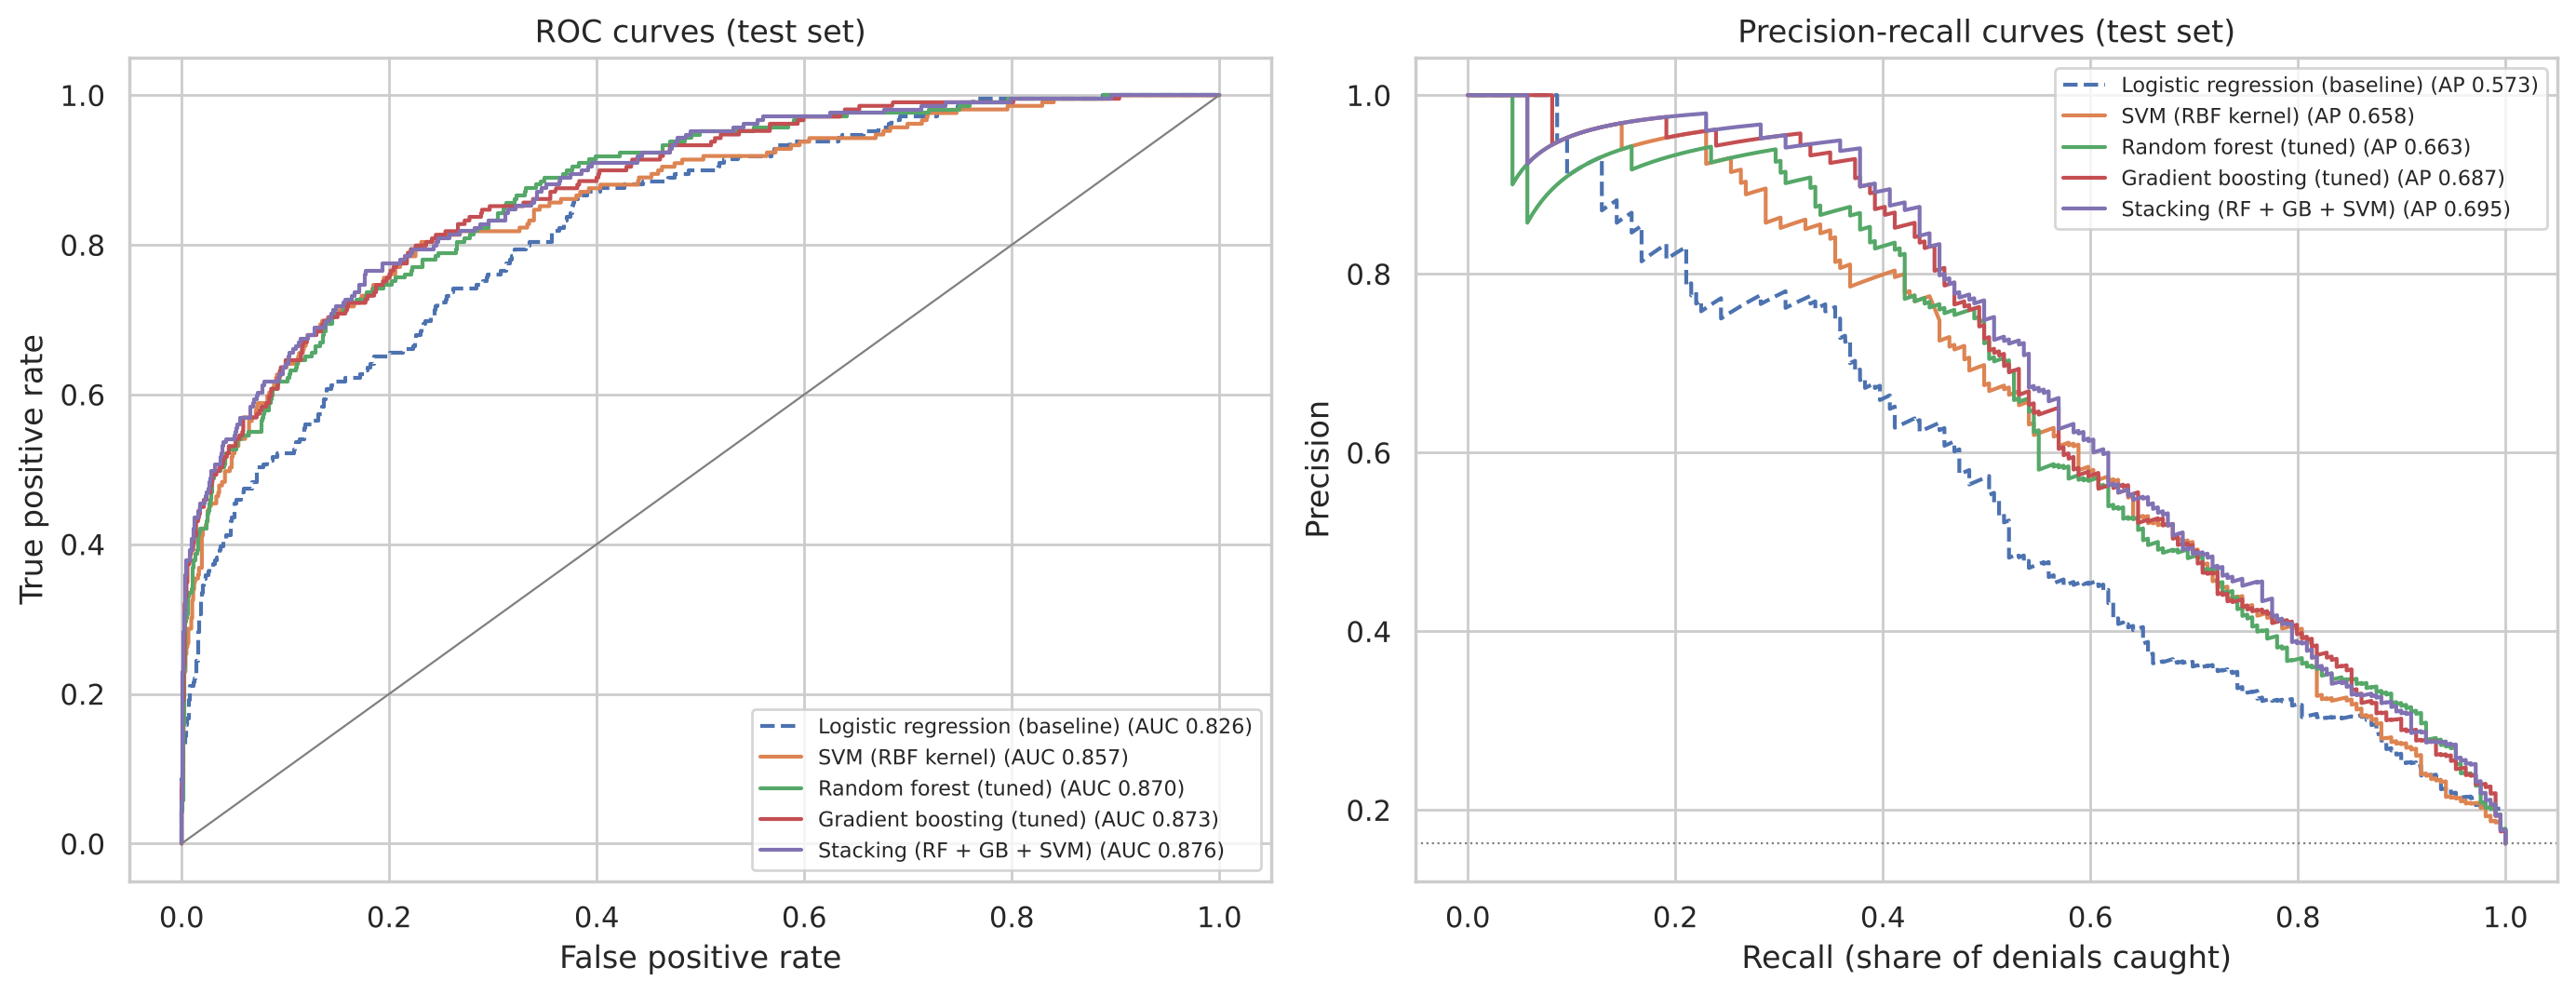

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for name, p in proba.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    prec, rec, _ = precision_recall_curve(y_test, p)
    ls = "--" if "baseline" in name else "-"
    axes[0].plot(fpr, tpr, ls, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
    axes[1].plot(rec, prec, ls, label=f"{name} (AP {average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], color="grey", lw=.8)
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curves (test set)"); axes[0].legend(fontsize=8, loc="lower right")
axes[1].axhline(y_test.mean(), color="grey", lw=.8, ls=":")
axes[1].set_xlabel("Recall (share of denials caught)"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curves (test set)"); axes[1].legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

**Champion model and operating threshold.** I choose the champion by test ROC-AUC, preferring the simpler model when the difference is under 0.005. A 0.5 cutoff is not meaningful when only 16% of applications are denied, so the threshold is chosen on **out-of-fold training predictions** to maximise F1. It is then applied unchanged to the test set.

In [14]:
best_auc = test_results["ROC-AUC"].max()
candidates = test_results[test_results["ROC-AUC"] >= best_auc - 0.005].index
simplicity = ["Random forest (tuned)", "Gradient boosting (tuned)", "SVM (RBF kernel)",
              "Stacking (RF + GB + SVM)", "Logistic regression (baseline)"]
CHAMP = next(m for m in simplicity if m in candidates)
champ = final[CHAMP]
print("Champion:", CHAMP)

oof = cross_val_predict(champ, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
grid = np.linspace(0.05, 0.9, 86)
f1s = [f1_score(y_train, oof >= t) for t in grid]
THR = grid[int(np.argmax(f1s))]
print(f"Threshold maximising out-of-fold F1: {THR:.2f}")

pred = (proba[CHAMP] >= THR).astype(int)
print(classification_report(y_test, pred, target_names=["Approved", "Denied"], digits=3))
print(f"Balanced accuracy = {balanced_accuracy_score(y_test, pred):.3f}")

Champion: Gradient boosting (tuned)


Threshold maximising out-of-fold F1: 0.25
              precision    recall  f1-score   support

    Approved      0.929     0.894     0.911      1078
      Denied      0.542     0.646     0.590       209

    accuracy                          0.854      1287
   macro avg      0.735     0.770     0.750      1287
weighted avg      0.866     0.854     0.859      1287

Balanced accuracy = 0.770


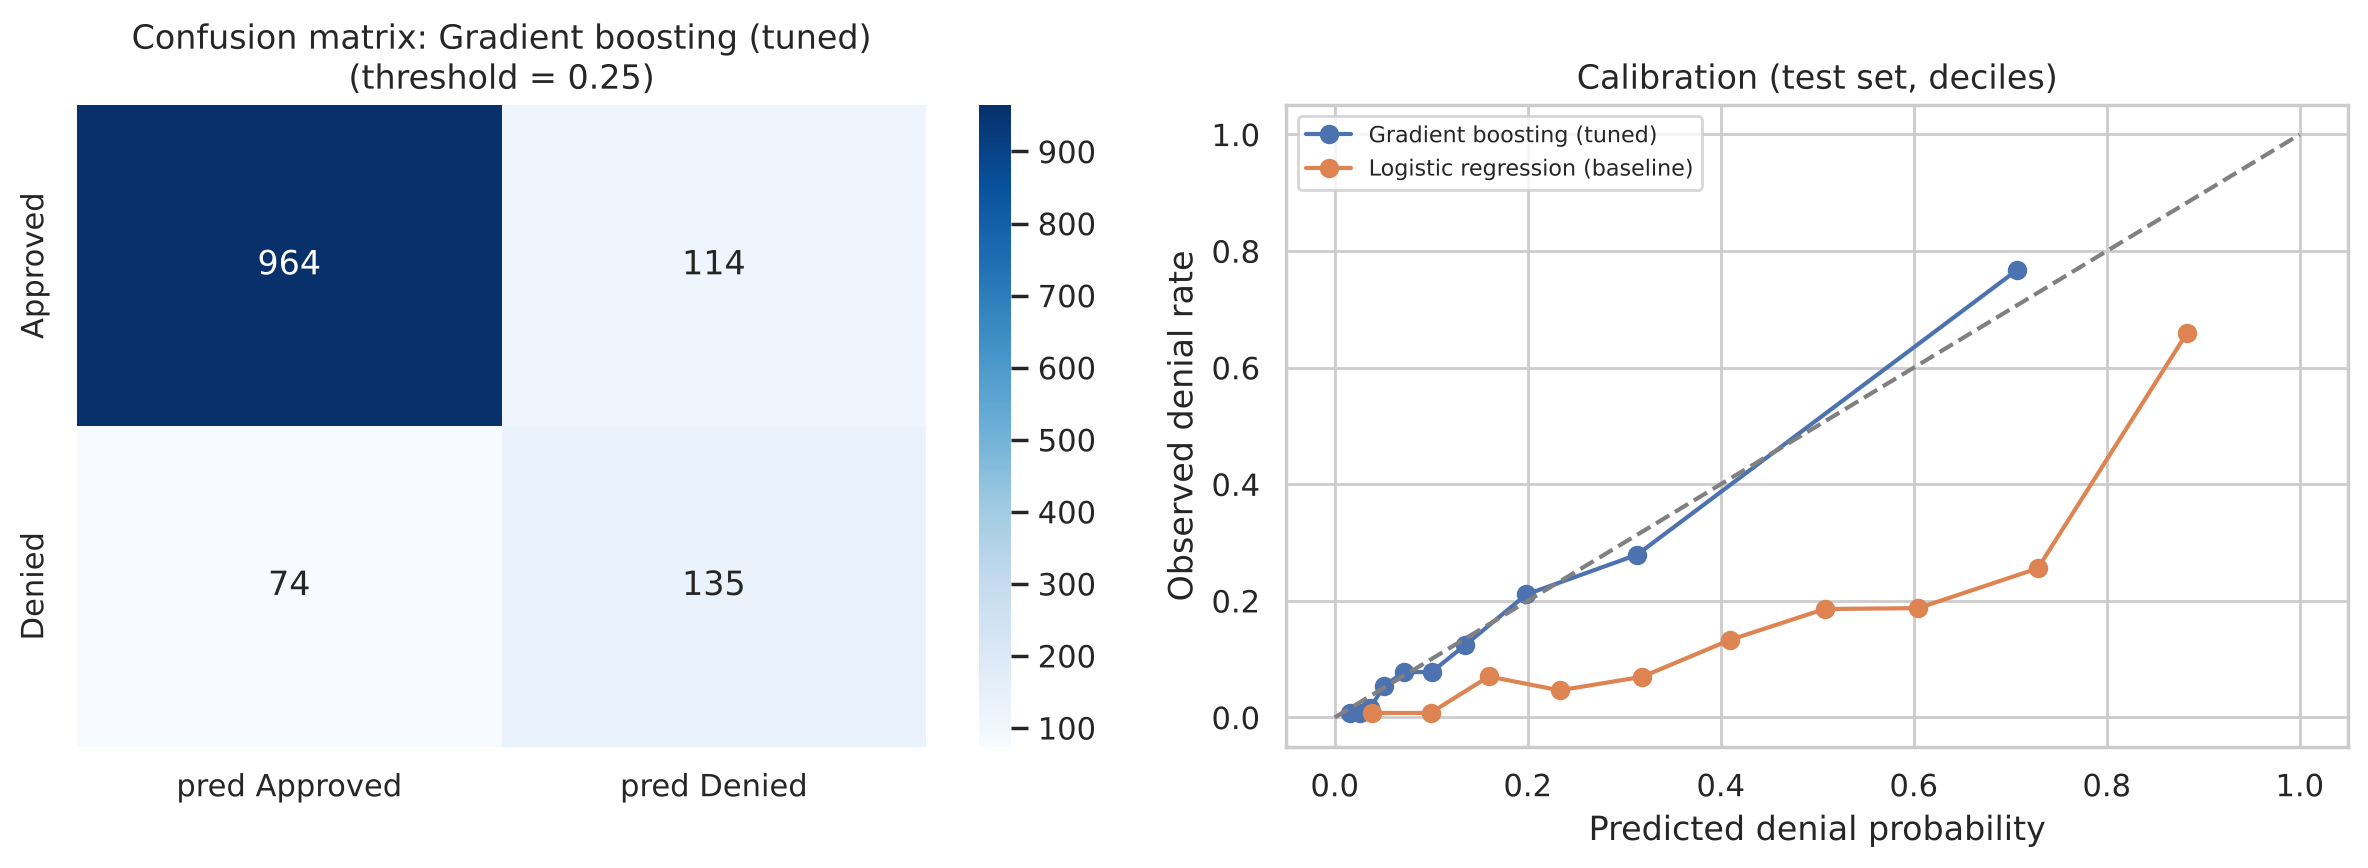

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["pred Approved", "pred Denied"], yticklabels=["Approved", "Denied"])
axes[0].set_title(f"Confusion matrix: {CHAMP}\n(threshold = {THR:.2f})")

for name in [CHAMP, "Logistic regression (baseline)"]:
    frac, mean_p = calibration_curve(y_test, proba[name], n_bins=10, strategy="quantile")
    axes[1].plot(mean_p, frac, "o-", label=name)
axes[1].plot([0, 1], [0, 1], color="grey", ls="--")
axes[1].set_xlabel("Predicted denial probability"); axes[1].set_ylabel("Observed denial rate")
axes[1].set_title("Calibration (test set, deciles)"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 7. Interpretation

**Permutation importance** on the test set: each *original* feature is shuffled in turn, and we measure the drop in ROC-AUC. Because the whole pipeline is permuted, a categorical feature counts once, not once per dummy column. This avoids the bias of impurity-based importance toward many-valued numeric features.

,importance,sd
dti,0.1085,0.0087
loan_purpose,0.0809,0.0085
log_property,0.0361,0.0046
ltv,0.0168,0.0049
aus,0.0101,0.0023
log_income,0.0062,0.0025
loan_type,0.0061,0.0024
loan_term,0.0056,0.0029
log_loan,0.0028,0.0030
has_coapplicant,0.0015,0.0010


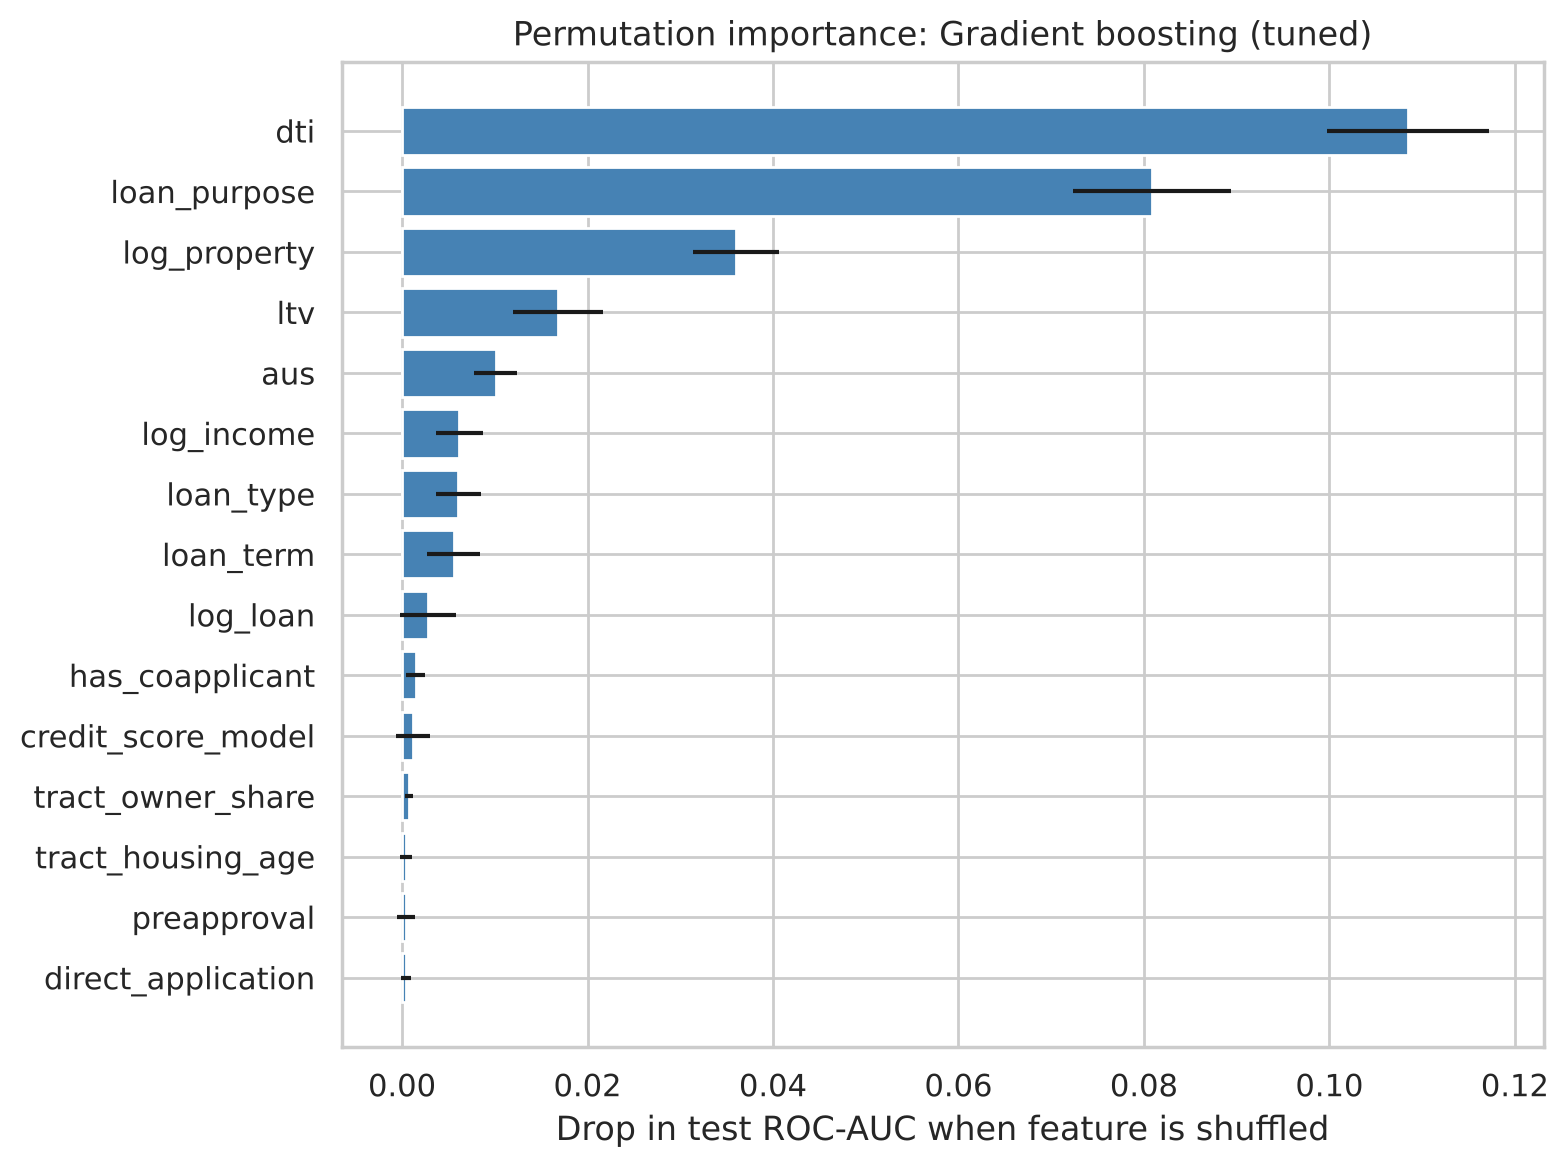

In [16]:
perm = permutation_importance(champ, X_test, y_test, scoring="roc_auc", n_repeats=15,
                              random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"importance": perm.importances_mean, "sd": perm.importances_std},
                   index=X_test.columns).sort_values("importance", ascending=False)
display(imp.round(4).head(15))

top = imp.head(15).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top.index, top["importance"], xerr=top["sd"], color="steelblue")
plt.xlabel("Drop in test ROC-AUC when feature is shuffled")
plt.title(f"Permutation importance: {CHAMP}"); plt.tight_layout(); plt.show()

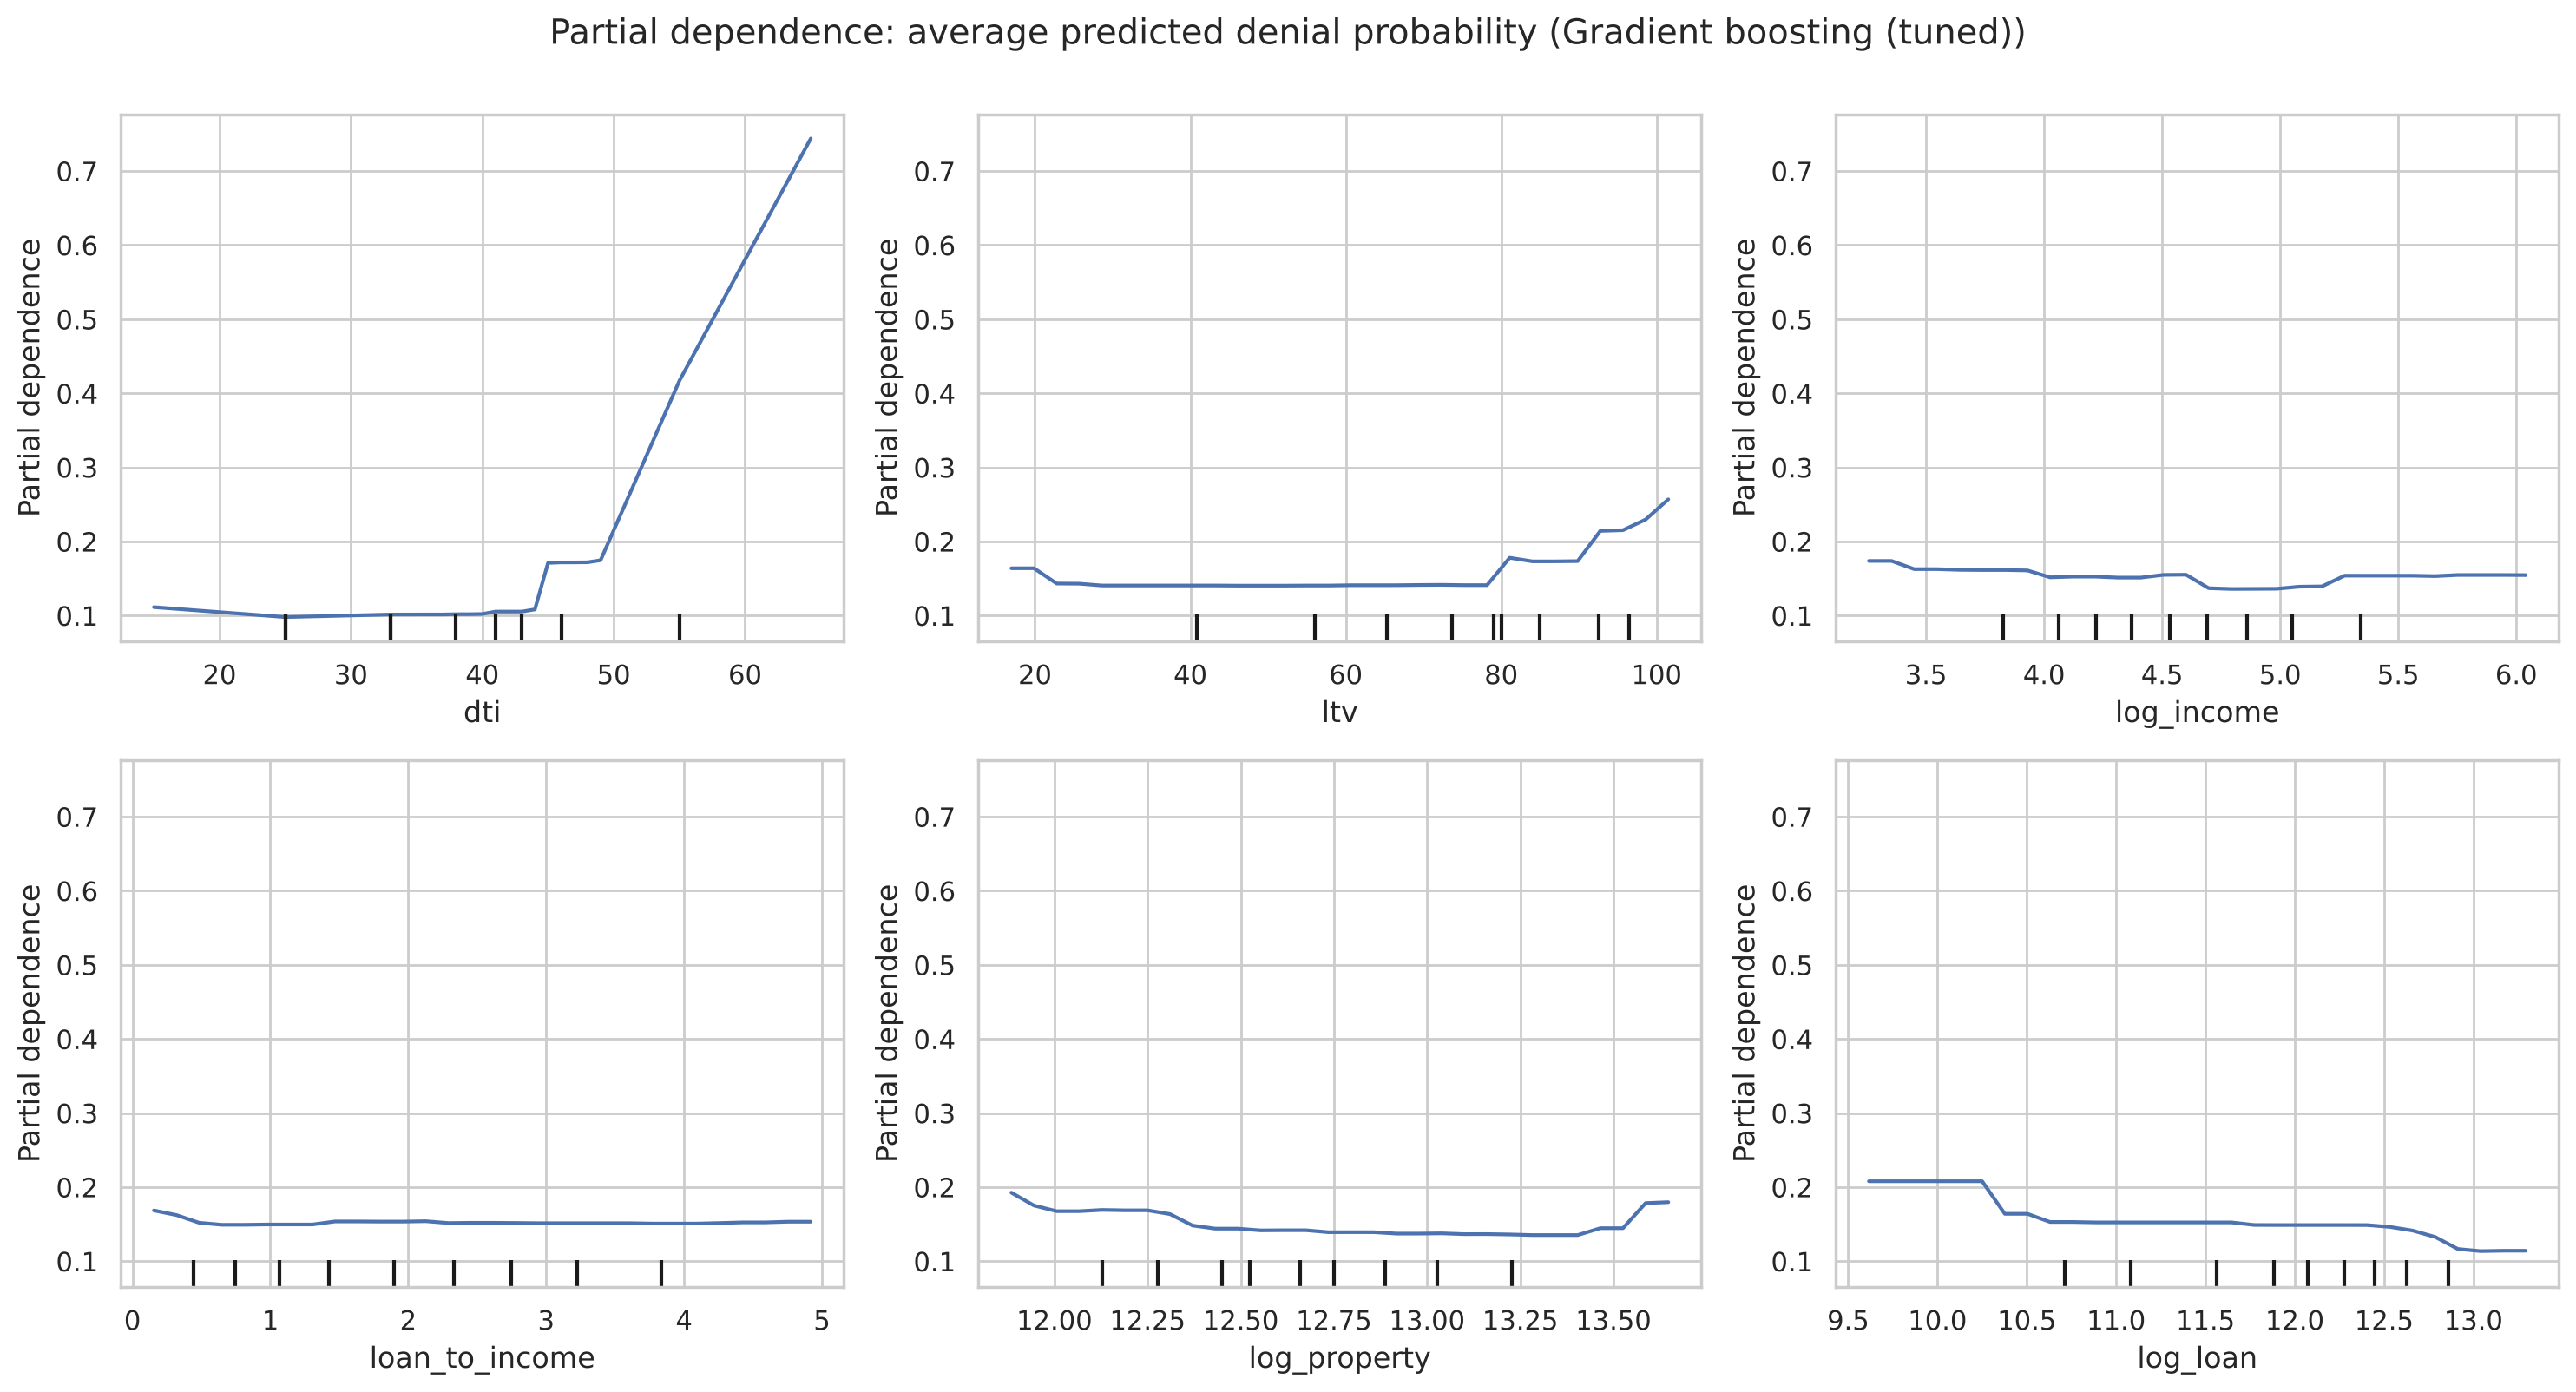

In [17]:
pd_feats = [f for f in ["dti", "ltv", "log_income", "loan_to_income", "log_property", "log_loan"]
            if f in imp.index][:6]
# The PD grid is computed from the feature's quantiles, so rows with missing values are excluded here
X_pd = X_train.dropna(subset=pd_feats)
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
PartialDependenceDisplay.from_estimator(champ, X_pd, pd_feats, ax=ax.ravel()[:len(pd_feats)],
                                        kind="average", grid_resolution=30,
                                        percentiles=(0.02, 0.98))
fig.suptitle(f"Partial dependence: average predicted denial probability ({CHAMP})", y=1.0)
plt.tight_layout(); plt.show()

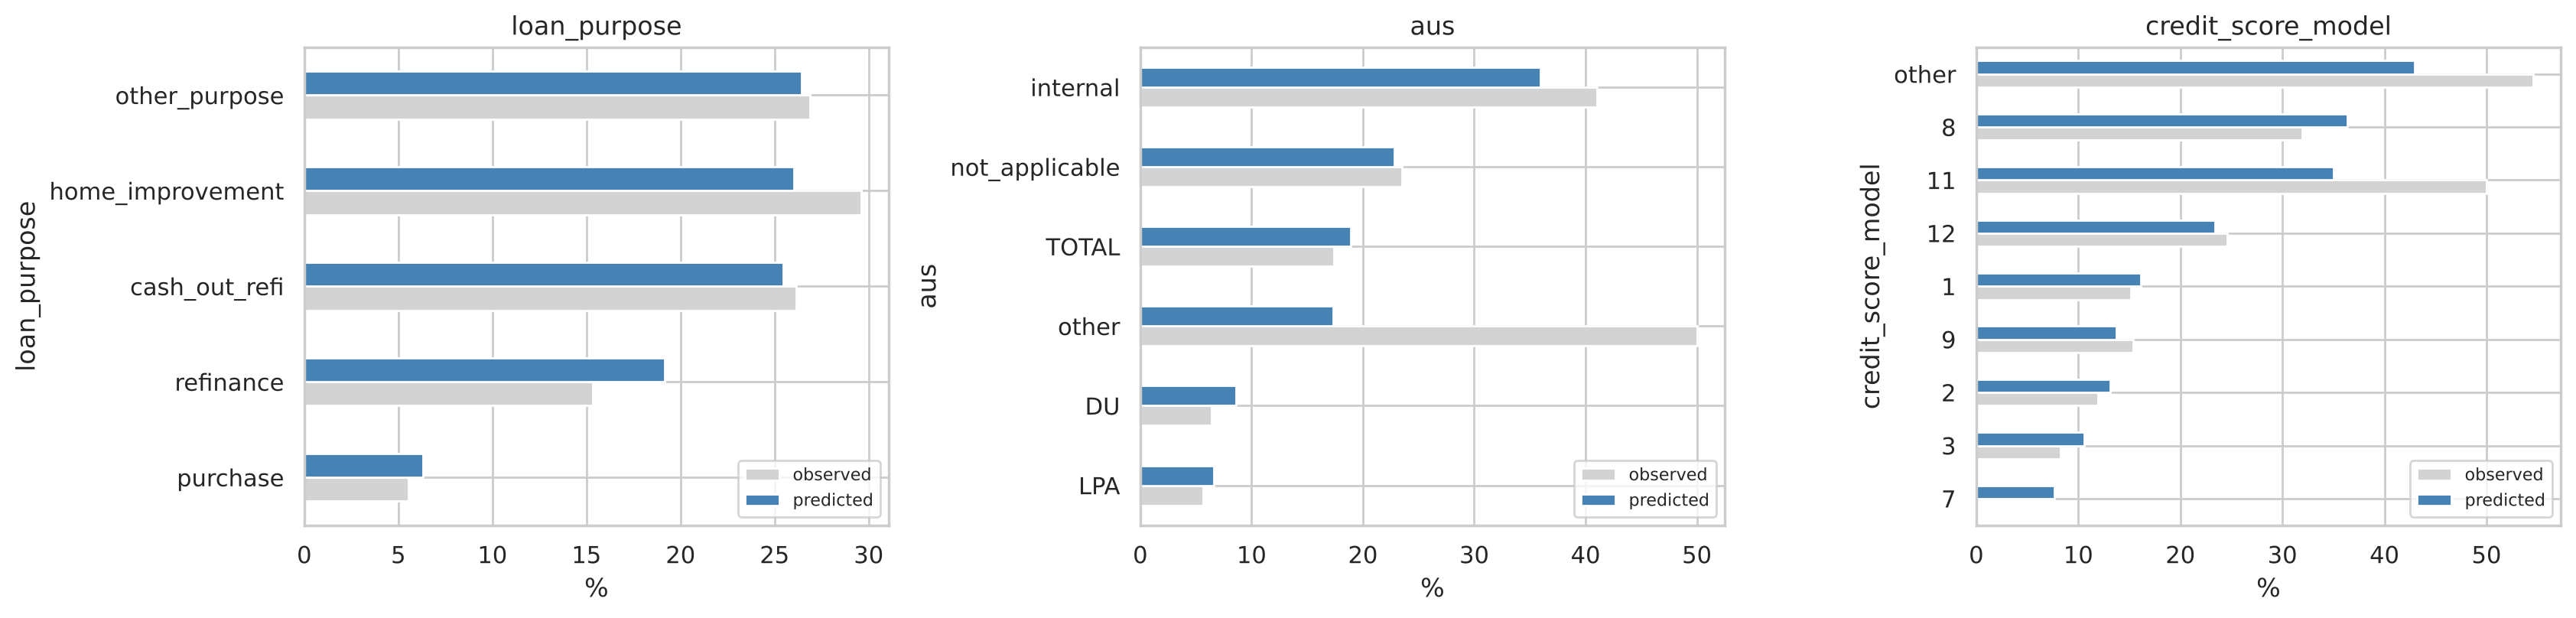

In [18]:
# Categorical drivers: average predicted denial probability by category (test set)
cat_view = X_test.assign(p=proba[CHAMP], denied=y_test.values)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, c in zip(axes, ["loan_purpose", "aus", "credit_score_model"]):
    g = cat_view.groupby(c)[["denied", "p"]].mean().sort_values("p") * 100
    g.plot.barh(ax=ax, color=["lightgrey", "steelblue"])
    ax.set_xlabel("%"); ax.set_title(c); ax.legend(["observed", "predicted"], fontsize=8)
plt.tight_layout(); plt.show()

## 8. Fair-lending check (aggregate level only)

The model never sees race, sex or age. That does not guarantee its predictions are neutral, because other features can act as proxies. The table below compares, by group, the **observed** denial rate, the **average predicted probability**, the **share flagged** at the chosen threshold, and the **ROC-AUC within the group**.

The test set alone has too few applicants in some groups (for example, fewer than 30 Black applicants). The table therefore uses **5-fold out-of-fold predictions for all 5,147 applications**: each application is scored by a model that did not see it during training. Groups with fewer than 30 applications are omitted, in line with the aggregate-only commitment from Deliverable #1.

*Caveat:* as the FFIEC warns, HMDA lacks credit scores and other underwriting data, so differences here are descriptive and **not** evidence of discrimination by any lender.

In [19]:
oof_all = cross_val_predict(champ, X, y, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
flag_all = (oof_all >= THR).astype(int)
print(f"Out-of-fold ROC-AUC on all {len(y):,} applications: {roc_auc_score(y, oof_all):.3f}")

demo = df[["derived_race", "derived_sex", "applicant_age"]].copy()
demo["race"] = demo["derived_race"].where(demo["derived_race"].isin(
    ["White", "Asian", "Black or African American", "Race Not Available"]), "Other / joint")
demo["sex"] = demo["derived_sex"]
demo["age_62plus"] = np.where(demo["applicant_age"].isin(["65-74", ">74"]), "65+",
                     np.where(demo["applicant_age"] == "8888", "not available", "<65"))

def group_table(col):
    t = pd.DataFrame({"g": demo[col], "y": y.values, "p": oof_all, "flag": flag_all})
    out = t.groupby("g").apply(lambda s: pd.Series({
        "n": len(s), "observed denial %": s["y"].mean() * 100, "mean predicted %": s["p"].mean() * 100,
        "flagged %": s["flag"].mean() * 100,
        "ROC-AUC": roc_auc_score(s["y"], s["p"]) if s["y"].nunique() == 2 and len(s) >= 30 else np.nan}))
    out = out[out["n"] >= 30]
    out["n"] = out["n"].astype(int)
    return out.round({"observed denial %": 1, "mean predicted %": 1, "flagged %": 1, "ROC-AUC": 3})

for col in ["race", "sex", "age_62plus"]:
    print(f"\n=== {col} ==="); display(group_table(col))

Out-of-fold ROC-AUC on all 5,147 applications: 0.863

=== race ===


,n,observed denial %,mean predicted %,flagged %,ROC-AUC
g,,,,,
Asian,213,12.2,9.4,8.5,0.815
Black or African American,116,23.3,22.6,30.2,0.849
Other / joint,152,10.5,12.2,13.2,0.849
Race Not Available,683,20.1,17.3,19.9,0.851
White,3983,15.8,16.2,17.7,0.867



=== sex ===


,n,observed denial %,mean predicted %,flagged %,ROC-AUC
g,,,,,
Female,1120,21.9,21.5,25.9,0.873
Joint,1846,10.5,11.4,10.3,0.861
Male,1794,17.8,17.4,20.1,0.845
Sex Not Available,387,19.4,16.2,18.3,0.844



=== age_62plus ===


,n,observed denial %,mean predicted %,flagged %,ROC-AUC
g,,,,,
65+,744,20.0,21.2,25.5,0.812
<65,4286,15.7,15.3,16.5,0.870
not available,117,9.4,11.6,11.1,0.852


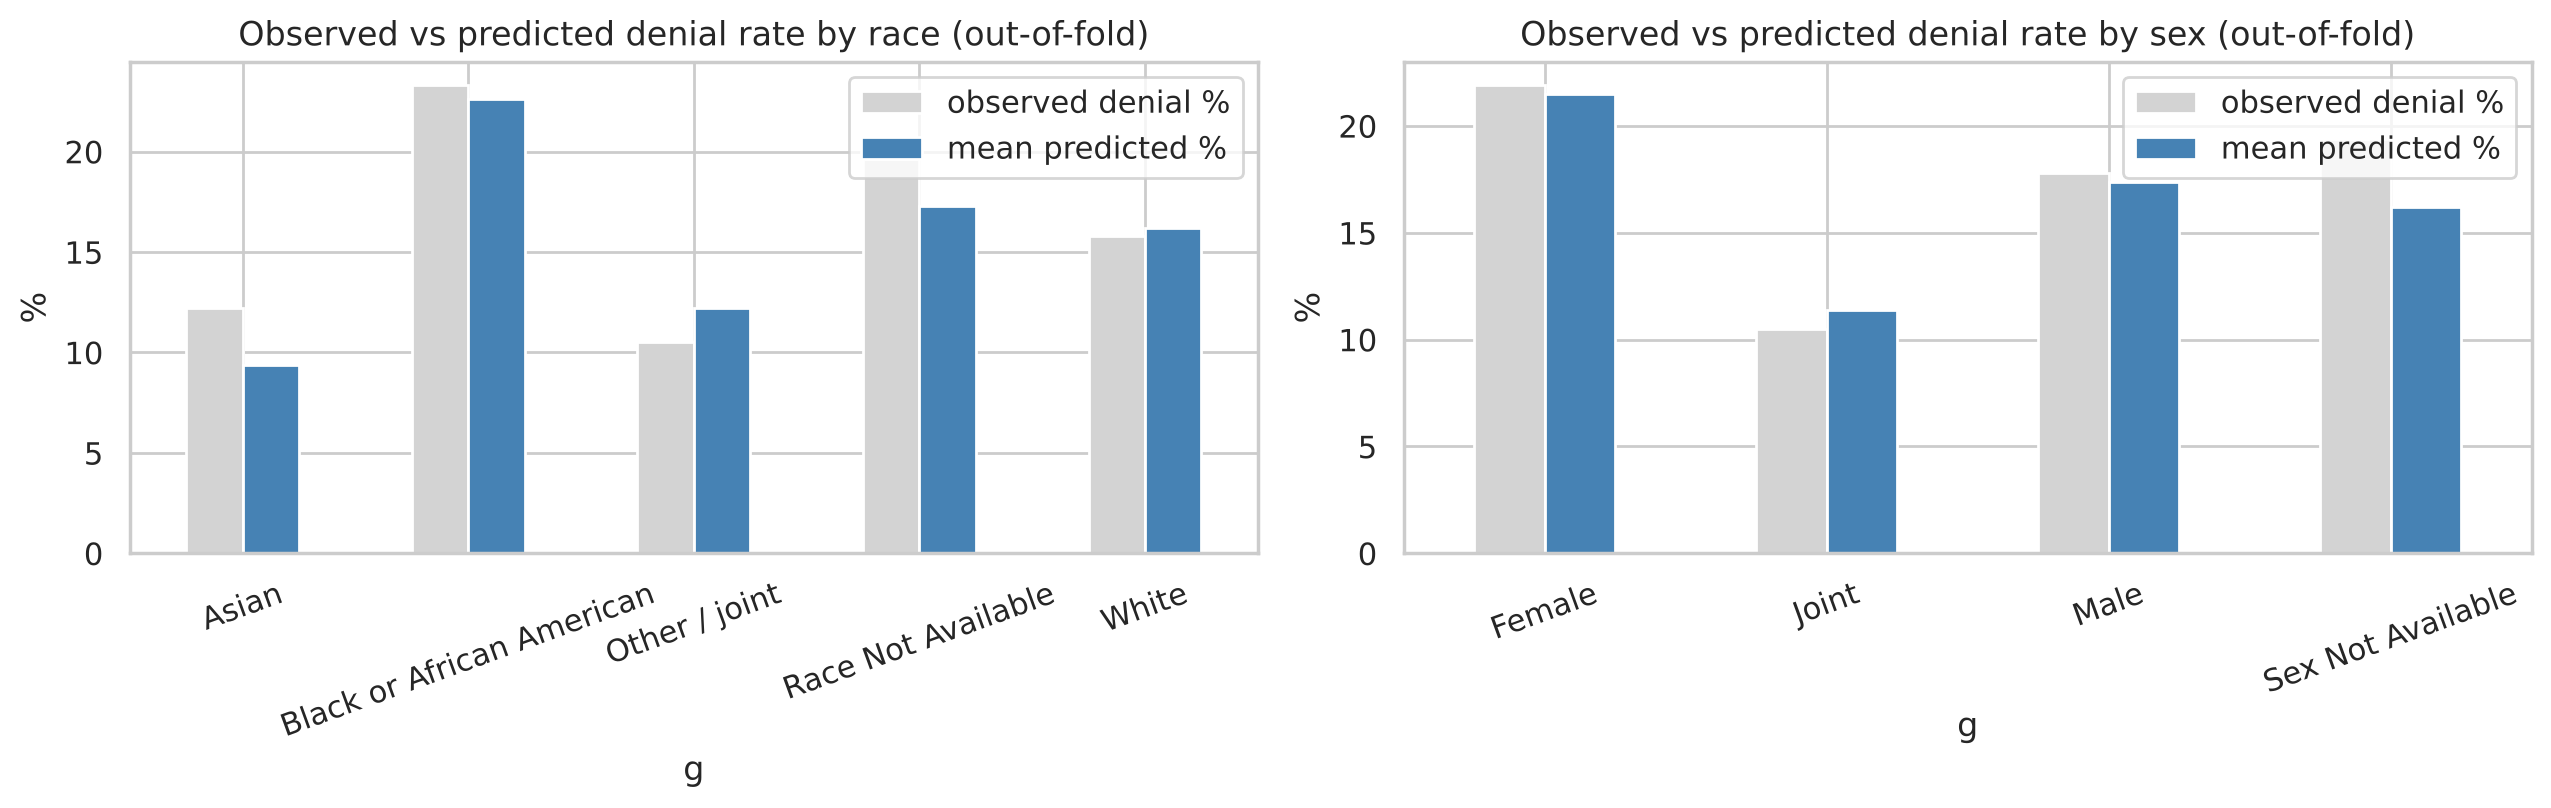

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, col in zip(axes, ["race", "sex"]):
    g = group_table(col)[["observed denial %", "mean predicted %"]]
    g.plot.bar(ax=ax, color=["lightgrey", "steelblue"], rot=20)
    ax.set_ylabel("%"); ax.set_title(f"Observed vs predicted denial rate by {col} (out-of-fold)")
plt.tight_layout(); plt.show()

## 9. One-page analysis

### Predicting mortgage denials in Tippecanoe County, 2025: one-page analysis

**Objective and data.** Using the 2025 HMDA Loan/Application Register for Tippecanoe County, IN (Deliverable #1), I asked how well a lender's decision to **deny** a mortgage application can be predicted from information available when the application is filed, and which factors drive that decision. The sample has the **5,147 applications on which a lender made a credit decision** (originated, approved but not accepted, or denied), from 238 lenders, excluding partially exempt reporters. **16.2% (834) were denied.** I built 23 features (debt-to-income, combined LTV, loan amount, property value, income, loan-to-income, loan term, loan type and purpose, lien, occupancy, AUS used, credit-score model and census-tract characteristics). I excluded fields reported only after origination (interest rate, rate spread, costs, HOEPA status, purchaser), which would leak the outcome. I also excluded race, sex, age and tract minority share, so the model follows fair-lending practice.

**Method (Week 6).** On a stratified 75% training set, I compared seven classifiers with 5-fold cross-validation: a decision tree, bagging, random forest, AdaBoost, gradient boosting (histogram GB), an RBF-kernel SVM and a logistic-regression baseline. I then tuned the random forest and gradient boosting with a randomized search, and built a **stacking** ensemble (random forest + gradient boosting + SVM, combined by a logistic meta-learner). Every model was scored once on the untouched 25% test set (1,287 applications).

**Results.** The **tree ensembles clearly beat the single tree and the linear baseline.** Cross-validated ROC-AUC was 0.853 for gradient boosting, 0.852 for the random forest, 0.847 for bagging, 0.841 for the SVM and 0.839 for AdaBoost, compared with 0.815 for logistic regression and 0.802 for a single tree. On the test set, stacking scored highest (**AUC 0.876**, PR-AUC 0.695), just ahead of tuned **gradient boosting (AUC 0.873, PR-AUC 0.687)**, the random forest (0.870) and the SVM (0.857). Because stacking adds only 0.003 AUC at three times the complexity, **I selected gradient boosting as the champion.** Its probabilities are also well calibrated (Brier 0.084, compared with 0.175 for the class-weighted logistic model). At a threshold of 0.25, chosen on out-of-fold training predictions, it catches **65% of denials with 54% precision**, and 89% of approved applications are classified correctly (balanced accuracy 0.77).

**What drives denials.** Permutation importance shows that the **debt-to-income ratio** dominates (removing it costs 0.11 AUC), followed by **loan purpose** (0.08), **property value** (0.04), **LTV** (0.02) and the **automated underwriting system** used (0.01). The partial-dependence plots show threshold behaviour that matches underwriting rules. Predicted denial probability is flat at about 10-11% up to a DTI of roughly 44%, jumps to about 17% at 45-49%, and then rises steeply to about 42% at 55% and about 74% above 60%. Risk is also flat up to an LTV of 80% and climbs to 21-26% above 90%. Purchase loans are rarely denied (6%), while home-improvement, cash-out refinance and other-purpose applications, often subordinate liens or home-equity lines, are denied 26-30% of the time.

**Fair-lending check.** Even without protected attributes, the model's predictions **reproduce the observed group differences**. Black applicants have an observed denial rate of 23.3% against a predicted 22.6%; for female applicants the figures are 21.9% and 21.5%; for White applicants, 15.8% and 16.2%. Discrimination ability is similar across groups (AUC 0.82-0.87), but somewhat lower for applicants 65+ (0.81). At the chosen threshold, 30% of Black applicants are flagged, compared with 18% of White applicants. These gaps come entirely from financial variables (mostly DTI and loan purpose), so a model like this would need an adverse-impact review before any operational use. Because HMDA lacks credit scores, these differences are **descriptive, not evidence of discrimination**.

**Limitations and next steps for the final project.** The main omitted variable is the credit score, which the public file does not include. The sample is a single county, and lender effects are not modelled. Some signals (for example, a missing property value, or no AUS used) partly reflect how far an application progressed. For the final report I plan to (1) add lender information through target encoding, (2) extend the sample to all of Indiana to test whether the results hold, (3) use SHAP values for applicant-level explanations, and (4) choose the decision threshold from explicit misclassification costs.